# Tutorial GN

This should be used after tutorial.ipynb. We had success with Newton's method in the last notebook. Now let's compare Newton and Gauss-Newton.

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


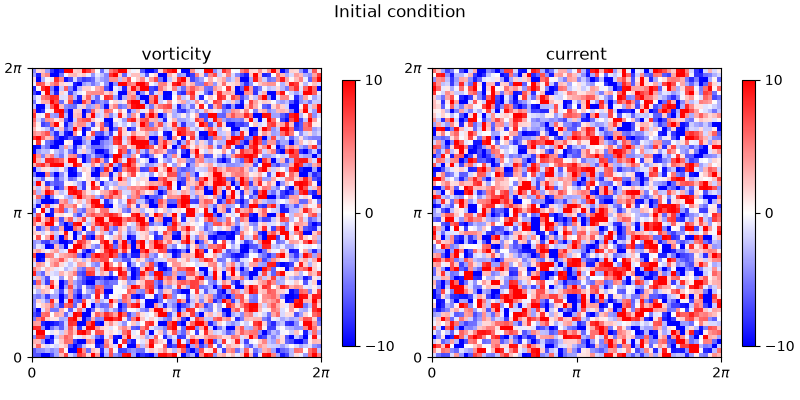

In [18]:
%load_ext autoreload
%autoreload 2

import lib.mhd_jax as mhd_jax
import lib.utils as utils
import jax.numpy as jnp

n    = 64               # grid resolution (n x n)
nu   = 1/100             # fluid dissipation
eta  = 1/100             # magnetic dissipation
b0   = [0.0, 0.1]       # mean magnetic field
u0   = [0.0, 0.0]       # mean flow field
seed = 111              # RNG seed for the random initial condition

# Forcing is specified as a string defining a lambda(x,y) -> vorticity forcing.
# Here: Kolmogorov forcing at wavenumber 4.
forcing_str = "lambda x,y : -4*jnp.cos(4*y)"

###############################
# Everything else (grid construction, dealiasing, random field generation)
# is handled for you inside utils.initialize_system
###############################
f0, param_dict = utils.initialize_system(n, nu, eta, b0, u0, seed, forcing_str)

figure, axis = mhd_jax.vis(f0, in_spectral=False, title="Initial condition")

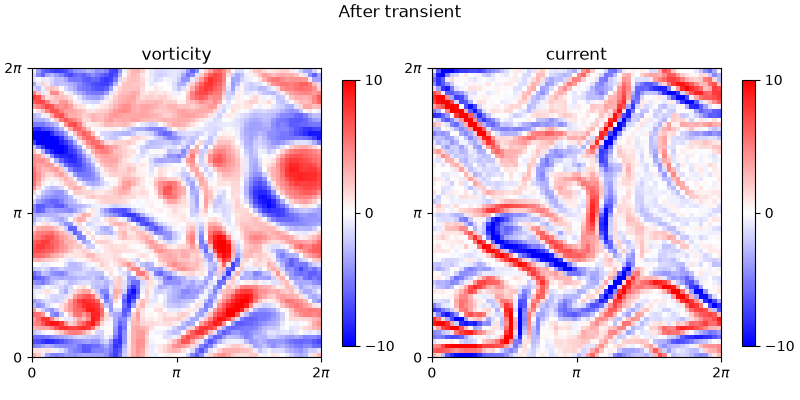

In [19]:
# Evolve a transient so our random initial condition relaxes onto the turbulent attractor.

dt = 1/128            # timestep
transient_time = 16.0  # total time to integrate the transient for

f = utils.evolve_transient(f0, param_dict, dt, transient_time)

figure, axis = mhd_jax.vis(f, in_spectral=True, title="After transient")

In [20]:
# Now that we have a sensible initial condition, integrate to build a timeseries
# and compute a recurrence diagram -- near-recurrences make good RPO guesses.

dt = 1/128
micro_steps = 16   # timesteps between saving
macro_steps = 64  # number of saved states

fs, dist = utils.generate_turbulent_trajectory(f, param_dict, dt, macro_steps, micro_steps)

Generating 64 steps of turbulence took 0.14810609817504883 seconds.
Recurrence diagram computed in 0.5663936138153076 seconds


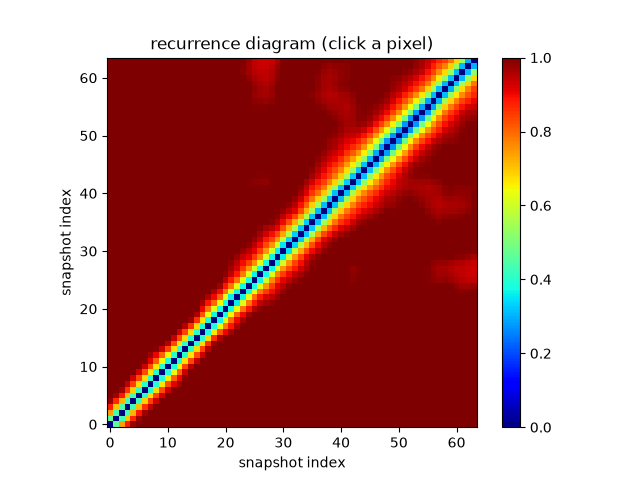

In [21]:
%matplotlib widget
# Bright streaks off the diagonal indicate near-recurrences -- good candidates for RPO guesses.
figure = utils.plot_recurrence_diagram(dist)

In [22]:
#Now we can make a guess at a recurrence. Zoom into the recurrence diagram near the
#diagonal: a dark pixel a short distance off the diagonal is a near-recurrence, a good
#RPO guess. Here we picked one by hand at i=152, j=170 this way.

idx = [27, 42]

#Append timestepping information as well
param_dict.update( {'dt': dt, 'ministeps': micro_steps, 'steps': macro_steps} )
turb_dict = {'fs': fs}
input_dict, param_dict = utils.create_state_from_turb(turb_dict, idx, param_dict)

Best symmetry found is (0.09817477042468103, 0, False)


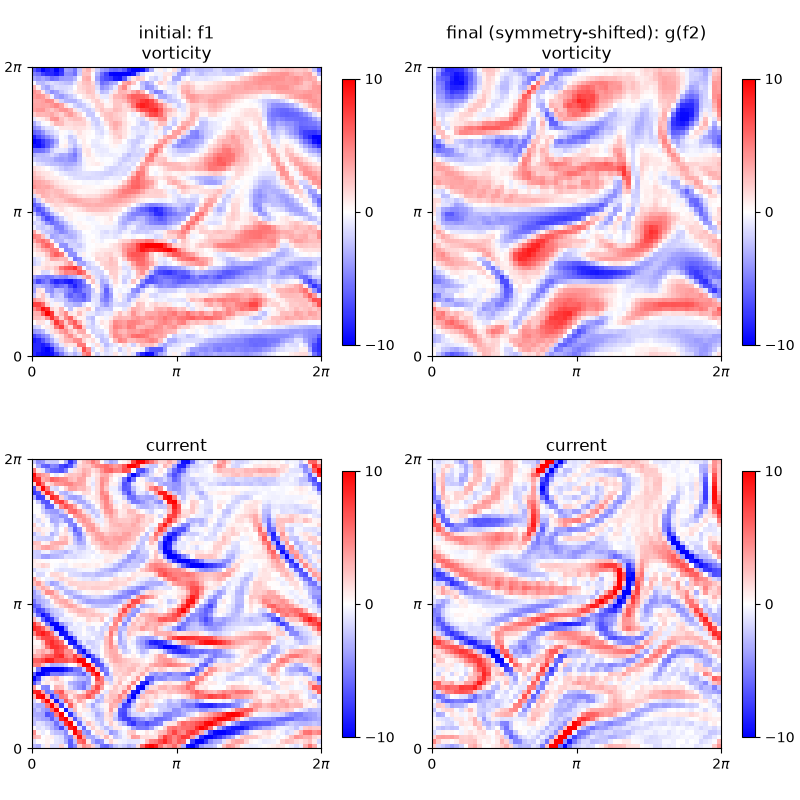

In [23]:
# Sanity check the guess: the initial snapshot and the symmetry-shifted final
# snapshot should look nearly identical if this is a good RPO candidate.
figure, axis = utils.compare_initial_final(turb_dict, idx, input_dict, param_dict)

In [24]:
#For fixed timestep solvers, we need to define parameters for checkpointing.
ministeps = 8
assert( param_dict['steps'] % ministeps == 0 )
param_dict.update({"ministeps": ministeps, "num_checkpoints": param_dict['steps']//ministeps })

maxit = 128          # number of ADAM steps
lr = 1e-2            # ADAM learning rate
save_every = 8       # checkpoint to disk every this many steps
min_abs_T = 0.3      # floor |T| away from 0 -- the loss has an exact minimum at T=0
                     # for any field (zero-duration integration is trivially the
                     # identity), so unconstrained descent would collapse there.

input_dict, history = utils.run_adjoint_descent(input_dict, param_dict, maxit=maxit, lr=lr,
                                                  save_every=save_every, min_abs_T=min_abs_T)

0: loss=16.158658, walltime=0.645, T=1.865, sx=0.088
1: loss=15.773464, walltime=0.001, T=1.855, sx=0.085
2: loss=15.408900, walltime=0.000, T=1.845, sx=0.088
3: loss=15.052803, walltime=0.000, T=1.835, sx=0.094
4: loss=14.707787, walltime=0.000, T=1.825, sx=0.101
5: loss=14.378458, walltime=0.000, T=1.815, sx=0.109
6: loss=14.069160, walltime=0.000, T=1.805, sx=0.118
7: loss=13.783741, walltime=0.000, T=1.795, sx=0.126
8: loss=13.525341, walltime=0.000, T=1.786, sx=0.135
9: loss=13.295987, walltime=0.000, T=1.776, sx=0.143
10: loss=13.095215, walltime=0.000, T=1.767, sx=0.149
11: loss=12.918192, walltime=0.000, T=1.759, sx=0.152
12: loss=12.756502, walltime=0.000, T=1.751, sx=0.154
13: loss=12.602030, walltime=0.000, T=1.744, sx=0.153
14: loss=12.449079, walltime=0.000, T=1.737, sx=0.152
15: loss=12.293967, walltime=0.000, T=1.732, sx=0.149
16: loss=12.134296, walltime=0.000, T=1.727, sx=0.147
17: loss=11.968491, walltime=0.000, T=1.723, sx=0.145
18: loss=11.795667, walltime=0.000, T=

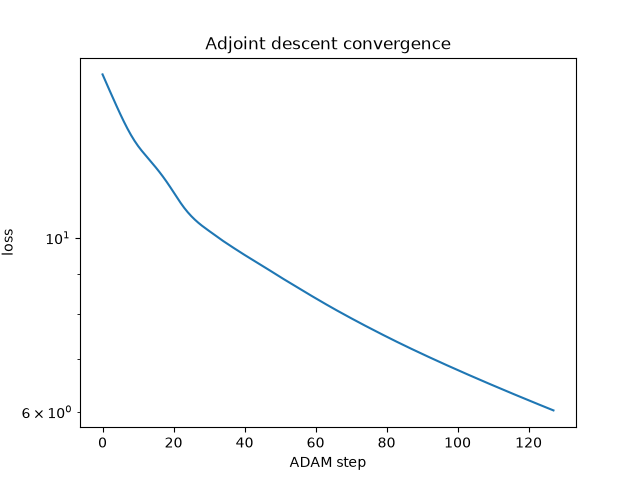

In [25]:
import matplotlib.pyplot as plt
plt.figure()
plt.semilogy(history)
plt.xlabel("ADAM step")
plt.ylabel("loss")
plt.title("Adjoint descent convergence")
plt.show()

## Newton vs Gauss-Newton ##
Adjoint descent gets us close, but convergence slows down a lot near the solution. We now fine-tune with Newton-GMRES.

Both variants solve the same Newton step with GMRES, computing Jacobian actions via `jax.jvp`. The only difference is `use_transpose`:
- **Newton** (`use_transpose=False`): solve $Js = -f$ directly.
- **Gauss-Newton** (`use_transpose=True`): precondition GMRES with the Jacobian transpose, equivalent to solving the normal equations $(J^TJ)s = -J^Tf$.

Gauss-Newton typically needs far fewer Krylov directions per step and tolerates larger steps, at the cost of being a descent method (it can in principle stall at a local minimum of $|f|^2$ rather than a true root).

In [28]:
import copy

# Load the most recently saved adjoint-descent checkpoint as our starting guess.
#newton_input_dict, newton_param_dict = utils.load_latest_checkpoint("temp_data/adjoint_descent")
newton_input_dict, newton_param_dict = input_dict, param_dict

###############################
# Newton / Gauss-Newton parameters -- the only things you need to touch
###############################

maxit = 10     # number of Newton/Gauss-Newton steps
inner = 16    # GMRES Krylov subspace dimension -- small on purpose, to show
              # Gauss-Newton tolerating it while plain Newton struggles
mode = "RK4"  # timestepping scheme used inside the objective
min_abs_T = 0.3  # same trivial-root issue as adjoint descent -- GN/Newton's own
                 # root-finding can also walk into the T=0 solution, so floor it here too

# Run both methods from identical copies of the same starting guess.
newton_out, newton_history = utils.run_newton(
    copy.deepcopy(newton_input_dict), copy.deepcopy(newton_param_dict),
    use_transpose=False, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

gn_out, gn_history = utils.run_newton(
    copy.deepcopy(newton_input_dict), copy.deepcopy(newton_param_dict),
    use_transpose=True, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

Evaluating objective: 4.48e-05 seconds
Evaluating Jacobian: 3.67e-05 seconds
0: rel_err=7.558e-01, |f|=2.216e+02, gmres_rel_res=8.593e-01, T=1.382, sx=0.082
1: rel_err=7.651e-01, |f|=2.144e+02, gmres_rel_res=9.121e-01, T=1.280, sx=0.077
2: rel_err=6.436e-01, |f|=1.807e+02, gmres_rel_res=8.741e-01, T=1.095, sx=0.065
3: rel_err=5.810e-01, |f|=1.618e+02, gmres_rel_res=8.340e-01, T=0.905, sx=0.051
4: rel_err=5.340e-01, |f|=1.438e+02, gmres_rel_res=7.278e-01, T=0.703, sx=0.039
5: rel_err=3.790e-01, |f|=1.193e+02, gmres_rel_res=2.390e-01, T=0.300, sx=-0.004
6: rel_err=8.323e-01, |f|=2.454e+02, gmres_rel_res=2.035e-01, T=0.300, sx=-0.000
7: rel_err=6.277e-01, |f|=1.802e+02, gmres_rel_res=2.263e-01, T=0.300, sx=0.000
8: rel_err=5.592e-01, |f|=1.581e+02, gmres_rel_res=2.586e-01, T=0.300, sx=-0.001
9: rel_err=5.071e-01, |f|=1.434e+02, gmres_rel_res=2.649e-01, T=0.300, sx=-0.001
Evaluating objective: 3.24e-05 seconds
Evaluating Jacobian: 3.86e-05 seconds
0: rel_err=8.060e-01, |f|=2.216e+02, gmres

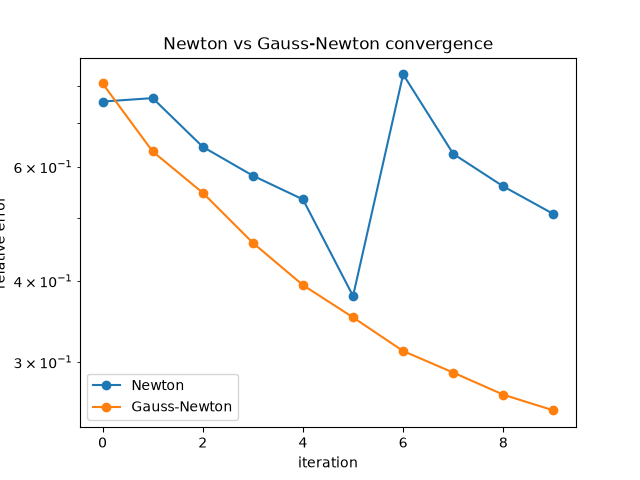

In [29]:
figure = utils.plot_newton_comparison([newton_history, gn_history], ["Newton", "Gauss-Newton"])

In [30]:
import lib.dictionaryIO as dictionaryIO

#Save to npz file for animation
dictionaryIO.save_dicts( f"temp_data/tutorial_gn_output", gn_out, newton_param_dict )